In [1]:
# Загружаем данные о клиентах телеком-компании
import pandas as pd

df = pd.read_csv(r"C:\Users\volod\OneDrive\Рабочий стол\WA_Fn-UseC_-Telco-Customer-Churn.csv")   
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [11]:
df['Churn'].value_counts().reset_index() #Считаем количество ушедших и оставшихся клиентов

,Churn,count
0,No,5174
1,Yes,1869


<Axes: >

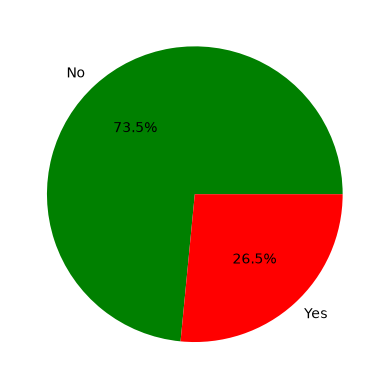

In [32]:
df['Churn'].value_counts().plot(kind = 'pie', autopct = '%1.1f%%',colors=['green', 'red'])  #График с оставшимися и ушедшими в процентном соотношении

In [40]:
df['Churn_num'] = df['Churn'].apply(lambda x: 1 if x == 'Yes' else 0)
df.groupby('Contract')['Churn_num'].mean().mul(100).round(2).sort_values(ascending=False).reset_index()  #Процент оттока в зависимости от типа контракта

,Contract,Churn_num
0,Month-to-month,42.71
1,One year,11.27
2,Two year,2.83


In [46]:
df.groupby('TechSupport') ['Churn_num'].mean().mul(100).round(2).reset_index() #Процент оттока в зависимости от наличия/отсутствия техподдержки

,TechSupport,Churn_num
0,No,41.64
1,No internet service,7.40
2,Yes,15.17


In [55]:
df['tenure_group'] = df['tenure'].apply(lambda x: '0-12' if x <=12 else ('13-24' if x<=24 else '25+'))
df.groupby('tenure_group') ['Churn_num'].mean().mul(100).round(2).reset_index() #Процент оттока в зависимости от длительности контракта

,tenure_group,Churn_num
0,0-12,47.44
1,13-24,28.71
2,25+,14.04


In [57]:
df.groupby('PaymentMethod') ['Churn_num'].mean().mul(100).round(2).reset_index() #Процент оттока в зависимости от способов оплаты


,PaymentMethod,Churn_num
0,Bank transfer (automatic),16.71
1,Credit card (automatic),15.24
2,Electronic check,45.29
3,Mailed check,19.11
